## Importing Libraries

In [1]:
import pandas as pd
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

## Configuration

In [2]:
class CFG:
    sequence_length = 1024
    vocab_size = 10000

## Loading the Data

In [3]:
negative_df = pd.read_csv("/kaggle/input/fake-news-detection/true.csv")
negative_df["fake"] = 0.0
positive_df = pd.read_csv("/kaggle/input/fake-news-detection/fake.csv")
positive_df["fake"] = 1.0
train_df = pd.concat([negative_df, positive_df])
train_df.head()

,title,text,subject,date,fake
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",0.0
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",0.0
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",0.0
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",0.0
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",0.0


## Exploring the Data

<Axes: xlabel='fake'>

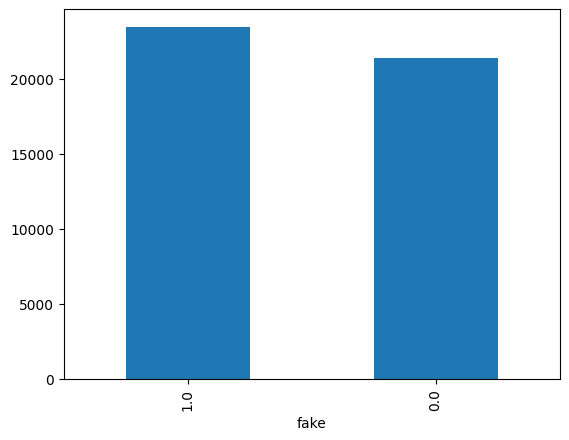

In [4]:
train_df.fake.value_counts().plot(kind="bar")

In [5]:
train_df["title_length"] = train_df["title"].apply(lambda title: len(title.split(" ")))
train_df["text_length"] = train_df["text"].apply(lambda text: len(text.split(" ")))

In [6]:
train_df[["title_length", "text_length"]].describe()

,title_length,text_length
count,44898.000000,44898.000000
mean,12.657245,415.760412
std,4.170713,361.648003
min,1.000000,1.000000
25%,10.000000,208.000000
50%,12.000000,371.000000
75%,15.000000,525.000000
max,45.000000,8436.000000


<Axes: ylabel='Frequency'>

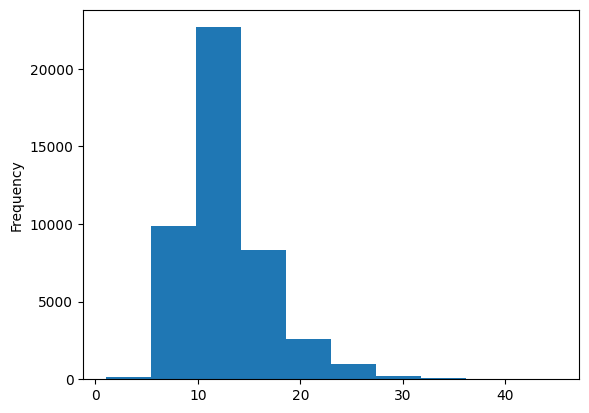

In [7]:
train_df["title_length"].plot(kind="hist")

<Axes: ylabel='Frequency'>

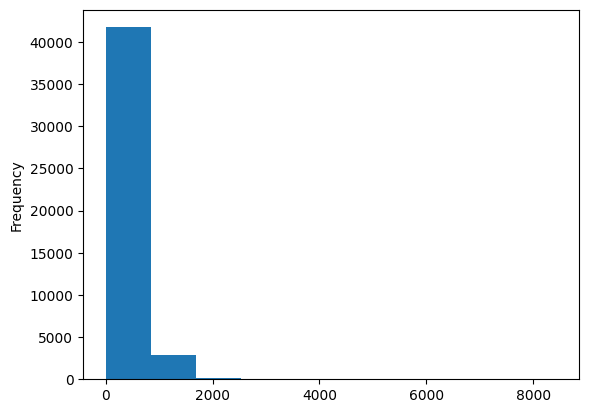

In [8]:
train_df["text_length"].plot(kind="hist")

## Create tensorflow dataset

In [9]:
train_data, valid_data = train_test_split(train_df, test_size=0.2, stratify=train_df["fake"], random_state=42)
train_data.shape, valid_data.shape

((35918, 7), (8980, 7))

In [10]:
def create_dataset(dataframe, shuffle=True):
    # Create a TensorFlow dataset from the text and fake columns of the dataframe
    dataset = tf.data.Dataset.from_tensor_slices((dataframe["text"], dataframe["fake"]))
    if shuffle:
         # Shuffle the dataset if the shuffle parameter is True
        dataset = dataset.shuffle(1024, reshuffle_each_iteration=True)
    # Batch the dataset into smaller batches of size 256
    dataset = dataset.batch(256).cache().prefetch(tf.data.AUTOTUNE)
    # Prefetch the next batch of data to further optimize training
    return dataset

Create tensorflow training dataset and validation dataset.

In [11]:
train_ds = create_dataset(train_data)
valid_ds = create_dataset(valid_data, shuffle=False)

[](http://)

## Training the LSTM Model

In [12]:
# Create a TextVectorization layer with specified parameters
vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=CFG.vocab_size, 
    output_sequence_length=CFG.sequence_length, 
    pad_to_max_tokens=True
)
# Adapt the TextVectorization layer to the training data
vectorizer.adapt(train_df["text"], batch_size=1024)

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 text_vectorization (TextVe  (None, 1024)              0         
 ctorization)                                                    
                                                                 
 embedding (Embedding)       (None, 1024, 64)          640000    
                                                                 
 bidirectional (Bidirection  (None, 1024, 128)         66048     
 al)                                                             
                                                                 
 bidirectional_1 (Bidirecti  (None, 64)                41216     
 onal)                                                           
                                                                 
 dense (Dense)               (None, 16)                1040      
                                                        

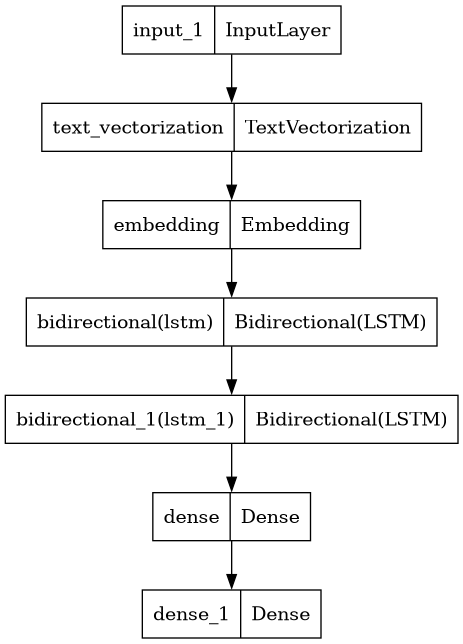

In [13]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(), dtype=tf.string),
    vectorizer,
    tf.keras.layers.Embedding(
        input_dim=CFG.vocab_size, 
        output_dim=64,
        input_length=CFG.sequence_length, 
        mask_zero=True
    ),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)), 
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32)), 
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])
model.compile(
    loss=tf.keras.losses.BinaryCrossentropy(), 
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), 
    metrics=[
        "accuracy", 
        tf.keras.metrics.AUC(name="auc")
    ]
)
model.summary()
tf.keras.utils.plot_model(model)

In [14]:
file_path = "model.tf"
history = model.fit(
    train_ds, 
    epochs=10, 
    validation_data=valid_ds,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            file_path,
            save_best_only=True,
            monitor='val_accuracy',
            mode='max'
        )
    ]
)

Epoch 1/10
141/141 [==============================] - 1037s 7s/step - loss: 0.1612 - accuracy: 0.9700 - auc: 0.9882 - val_loss: 0.0240 - val_accuracy: 0.9971 - val_auc: 0.9997
Epoch 2/10
141/141 [==============================] - 1003s 7s/step - loss: 0.0179 - accuracy: 0.9984 - auc: 0.9994 - val_loss: 0.0159 - val_accuracy: 0.9986 - val_auc: 0.9994
Epoch 3/10
141/141 [==============================] - 952s 7s/step - loss: 0.0115 - accuracy: 0.9995 - auc: 0.9997 - val_loss: 0.0127 - val_accuracy: 0.9986 - val_auc: 0.9995
Epoch 4/10
141/141 [==============================] - 953s 7s/step - loss: 0.0092 - accuracy: 0.9995 - auc: 0.9999 - val_loss: 0.0136 - val_accuracy: 0.9980 - val_auc: 0.9995
Epoch 5/10
141/141 [==============================] - 959s 7s/step - loss: 0.0066 - accuracy: 0.9997 - auc: 0.9999 - val_loss: 0.0212 - val_accuracy: 0.9957 - val_auc: 0.9986
Epoch 6/10
141/141 [==============================] - 961s 7s/step - loss: 0.0049 - accuracy: 0.9999 - auc: 0.9999 - val_lo

## Plot learning curve

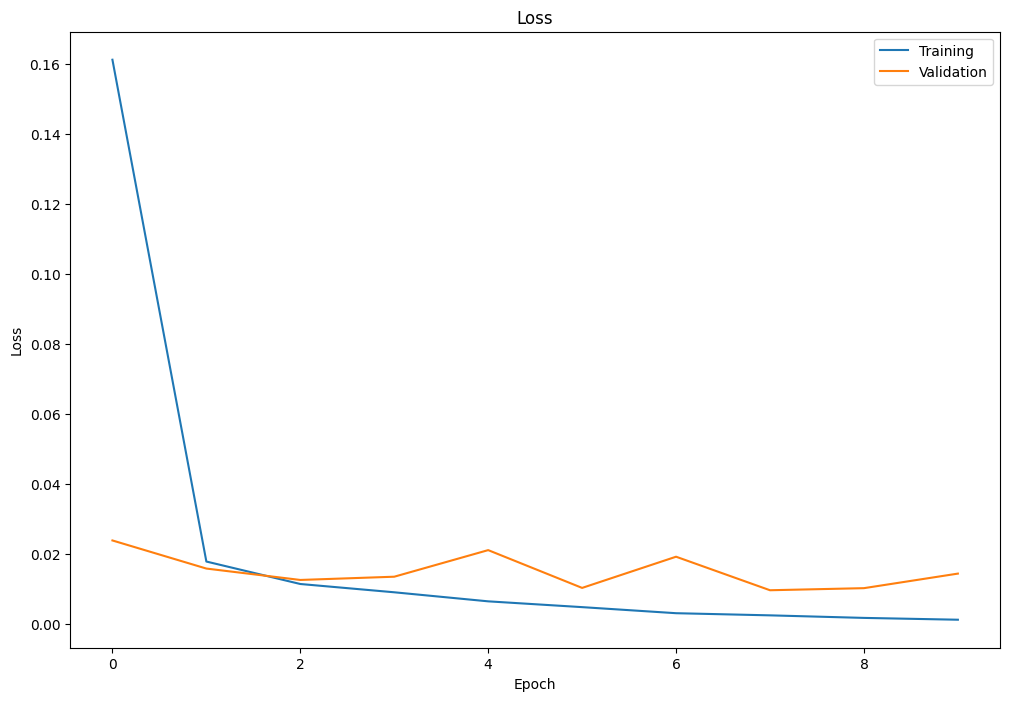

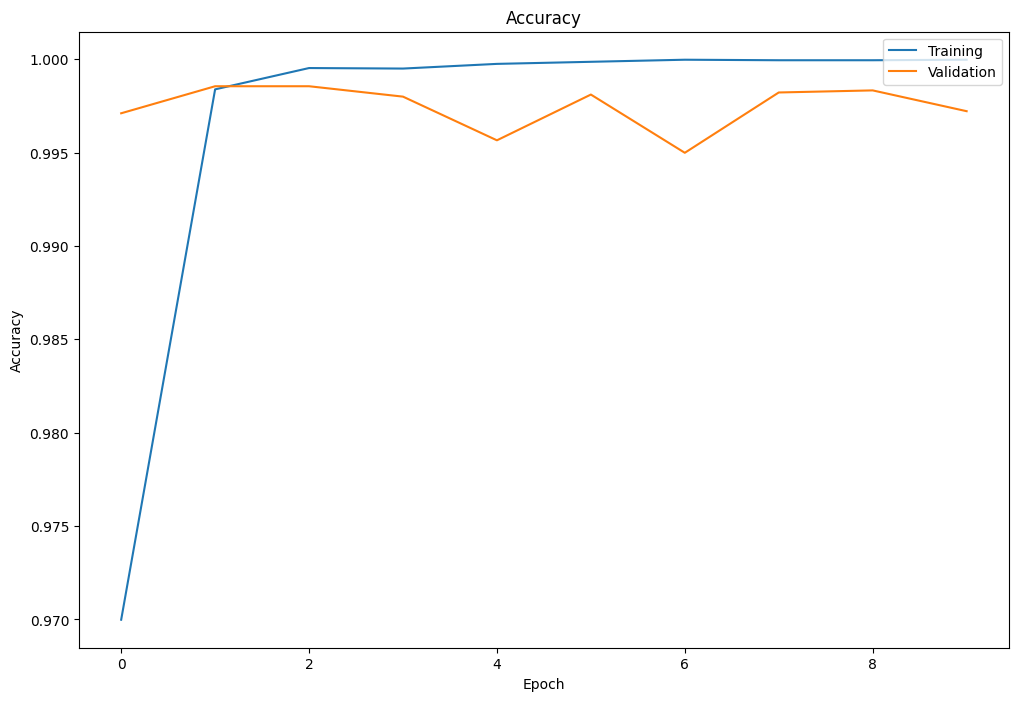

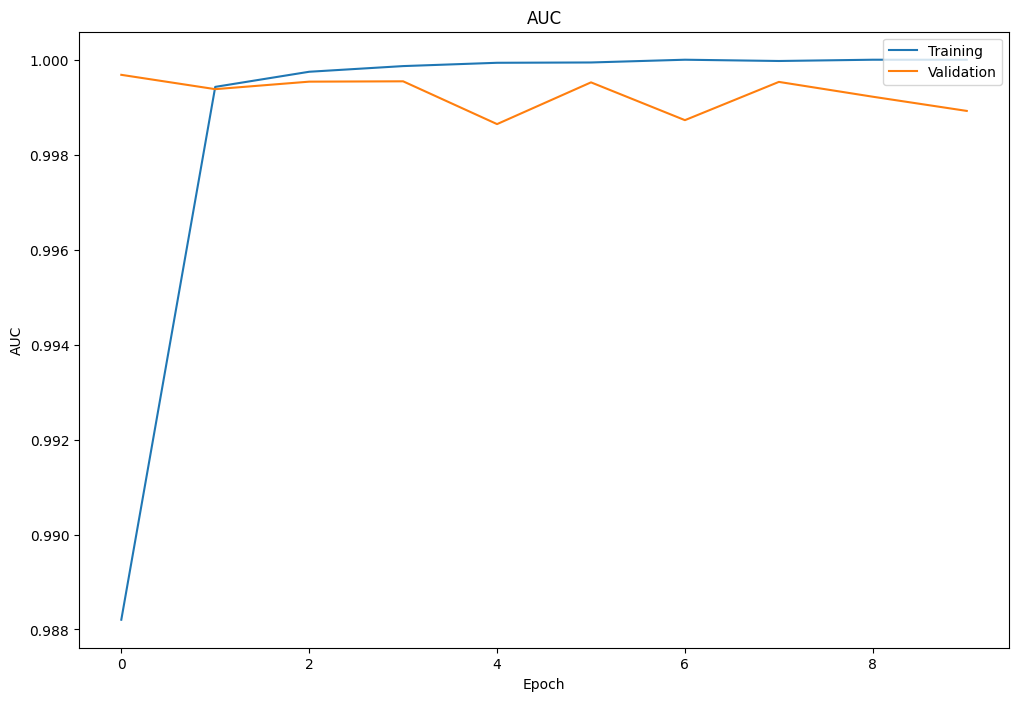

In [15]:
def plot_learning_curve(history):
  plt.figure(figsize=(12, 8))
  plt.plot(history.history['loss'])
  plt.plot(history.history['val_loss'])
  plt.title('Loss')
  plt.ylabel('Loss')
  plt.xlabel('Epoch')
  plt.legend(['Training', 'Validation'], loc='upper right')

  plt.figure(figsize=(12, 8))
  plt.plot(history.history['accuracy'])
  plt.plot(history.history['val_accuracy'])
  plt.title('Accuracy')
  plt.ylabel('Accuracy')
  plt.xlabel('Epoch')
  plt.legend(['Training', 'Validation'], loc='upper right')

  plt.figure(figsize=(12, 8))
  plt.plot(history.history['auc'])
  plt.plot(history.history['val_auc'])
  plt.title('AUC')
  plt.ylabel('AUC')
  plt.xlabel('Epoch')
  plt.legend(['Training', 'Validation'], loc='upper right')
  plt.show()
plot_learning_curve(history)